In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
data = pd.read_csv('../Resources/games_data.csv', index_col=0)


In [36]:
moves = data['moves'].str.split(' ')
print(moves.head())

id
TZJHLljE    [d4, d5, c4, c6, cxd5, e6, dxe6, fxe6, Nf3, Bb...
l1NXvwaE    [d4, Nc6, e4, e5, f4, f6, dxe5, fxe5, fxe5, Nx...
mIICvQHh    [e4, e5, d3, d6, Be3, c6, Be2, b5, Nd2, a5, a4...
kWKvrqYL    [d4, d5, Nf3, Bf5, Nc3, Nf6, Bf4, Ng4, e3, Nc6...
9tXo1AUZ    [e4, e5, Nf3, d6, d4, Nc6, d5, Nb4, a3, Na6, N...
Name: moves, dtype: object


In [37]:
def parse_move(move, index) -> tuple[int, int]:
    # Check if the move is a castling move
    if move == 'O-O':
        if index % 2 == 0:  # White's turn
            return (7, 1)  # g1
        else:  # Black's turn
            return (7, 8)  # g8
    elif move == 'O-O-O':
        if index % 2 == 0:  # White's turn
            return (3, 1)  # c1
        else:  # Black's turn
            return (3, 8)  # c8
    
    # Check if the move is a promotion move
    if '=' in move:
        move = move.split('=')[0]  # Remove the promotion part

    # Remove any check or checkmate symbols
    move = move.strip('#+')

    # Extract the target square (last two characters)
    target_square = move[-2:]

    # Convert the target square to coordinates
    file = ord(target_square[0].lower()) - ord('a') + 1
    rank = int(target_square[1])

    return (file, rank)

In [38]:
# Parse each move into its target square (E4 -> [5, 4])
moves_parsed = moves.apply(
    lambda game: [
        parse_move(move.rstrip("+#"), i) for i, move in enumerate(game)
    ]
)
moves_parsed.head()

id
TZJHLljE    [(4, 4), (4, 5), (3, 4), (3, 6), (4, 5), (5, 6...
l1NXvwaE    [(4, 4), (3, 6), (5, 4), (5, 5), (6, 4), (6, 6...
mIICvQHh    [(5, 4), (5, 5), (4, 3), (4, 6), (5, 3), (3, 6...
kWKvrqYL    [(4, 4), (4, 5), (6, 3), (6, 5), (3, 3), (6, 6...
9tXo1AUZ    [(5, 4), (5, 5), (6, 3), (4, 6), (4, 4), (3, 6...
Name: moves, dtype: object

In [39]:
def create_heatmap(moves_parsed):
    heatmap = np.zeros((8, 8))
    for game in moves_parsed:
        for move in game:
            if move is not None:
                file, rank = move
                heatmap[rank - 1, file - 1] += 1
    return heatmap

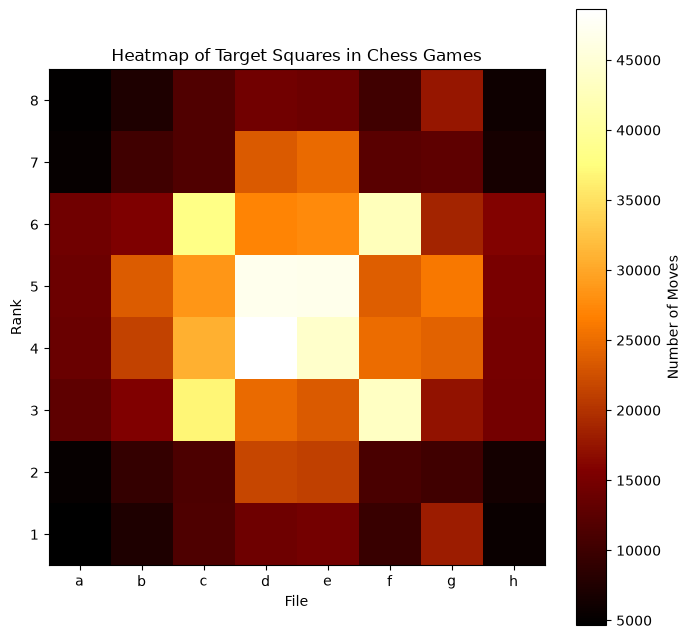

In [40]:
# Create a heatmap of the target squares
heatmap = create_heatmap(moves_parsed)

# Plot the heatmap 
plt.figure(figsize=(8, 8))
plt.imshow(heatmap[::-1], cmap='afmhot', interpolation='none')
plt.colorbar(label='Number of Moves')
plt.xticks(ticks=np.arange(8), labels=['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h'])
plt.yticks(ticks=np.arange(8), labels=np.arange(1, 9, )[::-1])
plt.title('Heatmap of Target Squares in Chess Games')
plt.xlabel('File')
plt.ylabel('Rank')
plt.savefig('../Resources/heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

What happens if we limit the heatmap to the last n moves? Will the heatmap look different if we look at only end games?

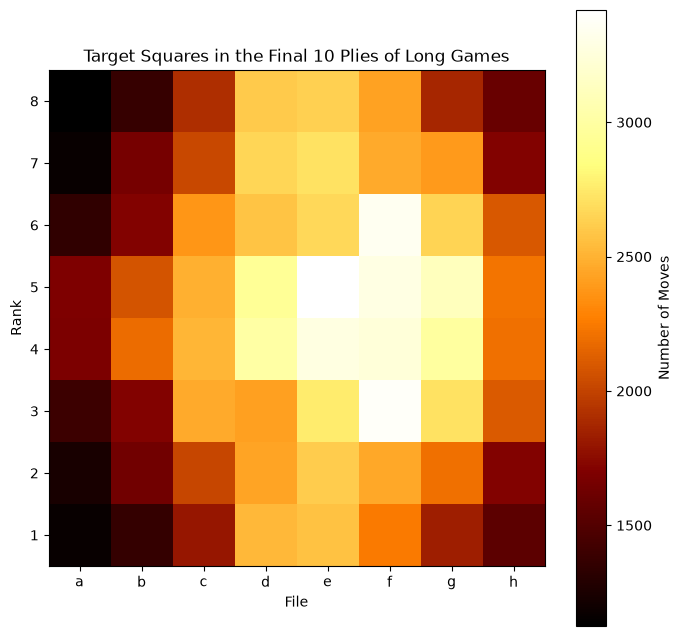

In [41]:
last_plies_limit = 10
games_with_enough_moves = moves_parsed[moves_parsed.apply(len) >= 40]

# Limit the moves to the last n moves of each game
moves_parsed_limit = games_with_enough_moves.apply(lambda game: game[-last_plies_limit:])

heatmap = create_heatmap(moves_parsed_limit)

# Plot the heatmap 
plt.figure(figsize=(8, 8))
plt.imshow(heatmap[::-1], cmap='afmhot', interpolation='none')
plt.colorbar(label='Number of Moves')
plt.xticks(ticks=np.arange(8), labels=['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h'])
plt.yticks(ticks=np.arange(8), labels=np.arange(1, 9, )[::-1])
plt.title(f'Target Squares in the Final {last_plies_limit} Plies of Long Games')
plt.xlabel('File')
plt.ylabel('Rank')
plt.show()